# Proyek Analisis Data: Bike Sharing
- **Nama:** Jody Ryand
- **Email:** jodyryand66@gmail.com
- **ID Dicoding:** jody_ryand4nb7

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Berapa rata-rata jumlah penyewaan sepeda harian (cnt) berdasarkan kondisi cuaca (weathersit) dan musim (season) sepanjang rentang tahun 2011 hingga 2012?
- **Pertanyaan 2:** Pada jam berapa saja terjadi lonjakan puncak (peak hours) volume penyewaan per jam antara pengguna terdaftar (registered) dan pengguna kasual (casual) pada hari kerja dibandingkan akhir pekan selama tahun 2011–2012?

## Import Semua Packages/Library yang Digunakan

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df day.csv

In [23]:
day_df = pd.read_csv('day.csv')
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load df hour.csv

In [24]:
hour_df = pd.read_csv('hour.csv')
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- xxx
- xxx

### Assessing Data

#### Identifying day.csv problem

In [25]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [26]:
day_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [27]:
day_df.duplicated().sum()

np.int64(0)

In [28]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Steps to Take:**
- **Mengubah tipe data kolom `dteday`**: Mengonversi kolom `dteday` dari tipe data `object` (string) menjadi tipe data `datetime` agar dapat diolah untuk analisis temporal/waktu.
- **Melakukan keterabacaan data (*Data Readability*)**: Mengubah nilai angka kategorikal pada kolom `season` (1–4) dan `weathersit` (1–3) menjadi label teks (misalnya: *Spring*, *Summer*, *Clear*, *Rain*) agar mempermudah interpretasi saat tahap pembuatan grafik/visualisasi.
- **Integritas Data**: Tidak ditemukan *missing values* (0 data hilang) maupun data duplikat (0 duplikasi), sehingga tidak diperlukan penanganan *imputation* atau penghapusan baris pada tahap *Cleaning Data*.

#### Identifying hour.csv problem

In [29]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [30]:
hour_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [31]:
hour_df.duplicated().sum()

np.int64(0)

In [32]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
- **Konversi Tipe Data**: Mengubah tipe data kolom `dteday` pada `hour_df` dari `object` menjadi `datetime64`.
- **Mapping Label Kategorikal**: Menyiapkan pemetaan (*mapping*) untuk kolom kategorikal seperti `season` dan `weathersit` agar lebih informatif saat tahap pembuatan visualisasi data.
- **Integritas Data**: Tidak ditemukan *missing values* (0 data hilang) maupun data duplikat (0 duplikasi), sehingga tidak diperlukan penanganan *imputation* atau penghapusan baris pada tahap *Cleaning Data*.

**Insight:** (Opsional)
- xxx
- xxx

### Cleaning Data

#### Fixing day.csv problem

In [33]:
# 1. Konversi tipe data dteday ke datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

# 2. Pemetaan label kategorikal untuk keterbacaan data (readability)
season_mapping = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}

day_df['season_label'] = day_df['season'].map(season_mapping)
day_df['weather_label'] = day_df['weathersit'].map(weather_mapping)

# 3. Verifikasi hasil cleaning day_df
print("--- Tipe Data day_df Setelah Cleaning ---")
print(day_df.dtypes[['dteday', 'season_label', 'weather_label']])

print("\n--- Sampel 5 Data Teratas day_df ---")
display(day_df[['dteday', 'season_label', 'weather_label', 'cnt']].head())

--- Tipe Data day_df Setelah Cleaning ---
dteday           datetime64[ns]
season_label             object
weather_label            object
dtype: object

--- Sampel 5 Data Teratas day_df ---


,dteday,season_label,weather_label,cnt
0,2011-01-01,Spring,Misty/Cloudy,985
1,2011-01-02,Spring,Misty/Cloudy,801
2,2011-01-03,Spring,Clear/Partly Cloudy,1349
3,2011-01-04,Spring,Clear/Partly Cloudy,1562
4,2011-01-05,Spring,Clear/Partly Cloudy,1600


#### Fixing hour.csv problem

In [34]:
# 1. Konversi tipe data dteday ke datetime
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Pemetaan label kategorikal untuk keterbacaan data (readability)
season_mapping = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}

hour_df['season_label'] = hour_df['season'].map(season_mapping)
hour_df['weather_label'] = hour_df['weathersit'].map(weather_mapping)

# 3. Verifikasi hasil cleaning hour_df
print("--- Tipe Data hour_df Setelah Cleaning ---")
print(hour_df.dtypes[['dteday', 'season_label', 'weather_label']])

print("\n--- Sampel 5 Data Teratas hour_df ---")
display(hour_df[['dteday', 'hr', 'season_label', 'weather_label', 'cnt']].head())

--- Tipe Data hour_df Setelah Cleaning ---
dteday           datetime64[ns]
season_label             object
weather_label            object
dtype: object

--- Sampel 5 Data Teratas hour_df ---


,dteday,hr,season_label,weather_label,cnt
0,2011-01-01,0,Spring,Clear/Partly Cloudy,16
1,2011-01-01,1,Spring,Clear/Partly Cloudy,40
2,2011-01-01,2,Spring,Clear/Partly Cloudy,32
3,2011-01-01,3,Spring,Clear/Partly Cloudy,13
4,2011-01-01,4,Spring,Clear/Partly Cloudy,1


**Insight:** (Opsional)
- xxx
- xxx

## Exploratory Data Analysis (EDA)

### Explore day.csv

In [35]:
day_df.describe(include='all')

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731,731
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,3
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Fall,Clear/Partly Cloudy
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,188,463
mean,366.000000,2012-01-01 00:00:00,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837,NaN,NaN
min,1.000000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000,NaN,NaN
25%,183.500000,2011-07-02 12:00:00,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000,NaN,NaN
50%,366.000000,2012-01-01 00:00:00,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000,NaN,NaN
75%,548.500000,2012-07-01 12:00:00,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000,NaN,NaN
max,731.000000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000,NaN,NaN


In [36]:
# 1. Eksplorasi Penyewaan Berdasarkan Musim
print("--- 1. Rata-rata & Distribusi Penyewaan Berdasarkan Musim ---")
season_eda = day_df.groupby('season_label').agg({
    'casual': 'mean',
    'registered': 'mean',
    'cnt': ['mean', 'median', 'min', 'max', 'std']
}).reset_index()
display(season_eda)

# 2. Eksplorasi Penyewaan Berdasarkan Cuaca
print("\n--- 2. Rata-rata & Distribusi Penyewaan Berdasarkan Cuaca ---")
weather_eda = day_df.groupby('weather_label').agg({
    'casual': 'mean',
    'registered': 'mean',
    'cnt': ['mean', 'median', 'min', 'max', 'std']
}).reset_index()
display(weather_eda)

# 3. Perbandingan Perilaku Pengguna pada Hari Kerja vs Hari Libur
print("\n--- 3. Rata-rata Penyewaan: Workingday vs Non-Workingday ---")
workingday_eda = day_df.groupby('workingday').agg({
    'casual': 'mean',
    'registered': 'mean',
    'cnt': 'mean'
}).reset_index()
workingday_eda['workingday'] = workingday_eda['workingday'].replace({0: 'Weekend/Holiday', 1: 'Working Day'})
display(workingday_eda)

# 4. Pertumbuhan Penyewaan Tahunan (2011 vs 2012)
print("\n--- 4. Total Volume Penyewaan Tahunan ---")
year_eda = day_df.groupby('yr').agg({
    'casual': 'sum',
    'registered': 'sum',
    'cnt': 'sum'
}).reset_index()
year_eda['yr'] = year_eda['yr'].replace({0: '2011', 1: '2012'})
display(year_eda)

--- 1. Rata-rata & Distribusi Penyewaan Berdasarkan Musim ---


season_label       casual   registered          cnt                      \
                       mean         mean         mean  median   min   max   
0         Fall  1202.611702  4441.691489  5644.303191  5353.5  1115  8714   
1       Spring   334.928177  2269.204420  2604.132597  2209.0   431  7836   
2       Summer  1106.097826  3886.233696  4992.331522  4941.5   795  8362   
3       Winter   729.112360  3999.050562  4728.162921  4634.5    22  8555   

                
           std  
0  1459.800381  
1  1399.942119  
2  1695.977235  
3  1699.615261


--- 2. Rata-rata & Distribusi Penyewaan Berdasarkan Cuaca ---


weather_label      casual   registered          cnt               \
                              mean         mean         mean  median  min   
0  Clear/Partly Cloudy  964.030238  3912.755940  4876.786177  4844.0  431   
1      Light Snow/Rain  185.476190  1617.809524  1803.285714  1817.0   22   
2         Misty/Cloudy  687.352227  3348.510121  4035.862348  4040.0  605   

                      
    max          std  
0  8714  1879.483989  
1  4639  1240.284449  
2  8362  1809.109918


--- 3. Rata-rata Penyewaan: Workingday vs Non-Workingday ---


,workingday,casual,registered,cnt
0,Weekend/Holiday,1371.134199,2959.034632,4330.168831
1,Working Day,606.570000,3978.250000,4584.820000



--- 4. Total Volume Penyewaan Tahunan ---


,yr,casual,registered,cnt
0,2011,247252,995851,1243103
1,2012,372765,1676811,2049576


### Explore hour.csv

In [37]:
hour_df.describe(include='all')

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379,17379
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,4
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Fall,Clear/Partly Cloudy
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4496,11413
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088,NaN,NaN
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,NaN,NaN
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000,NaN,NaN
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000,NaN,NaN
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000,NaN,NaN
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000,NaN,NaN


In [38]:
# 1. Rata-rata Penyewaan Berdasarkan Jam (hr)
print("--- 1. Rata-rata Penyewaan Berdasarkan Jam (hr) ---")
hourly_eda = hour_df.groupby('hr').agg({
    'casual': 'mean',
    'registered': 'mean',
    'cnt': ['mean', 'min', 'max']
}).reset_index()
display(hourly_eda.head(10))

# 2. Top 5 Jam Tersibuk pada Hari Kerja (Working Day = 1)
print("\n--- 2. Top 5 Jam Tersibuk pada Hari Kerja (Working Day) ---")
workingday_hourly = hour_df[hour_df['workingday'] == 1].groupby('hr').agg({
    'casual': 'mean',
    'registered': 'mean',
    'cnt': 'mean'
}).reset_index()

display(workingday_hourly.sort_values(by='cnt', ascending=False).head(5))

# 3. Top 5 Jam Tersibuk pada Akhir Pekan / Hari Libur (Working Day = 0)
print("\n--- 3. Top 5 Jam Tersibuk pada Akhir Pekan / Hari Libur ---")
non_workingday_hourly = hour_df[hour_df['workingday'] == 0].groupby('hr').agg({
    'casual': 'mean',
    'registered': 'mean',
    'cnt': 'mean'
}).reset_index()

display(non_workingday_hourly.sort_values(by='cnt', ascending=False).head(5))

--- 1. Rata-rata Penyewaan Berdasarkan Jam (hr) ---


hr     casual  registered         cnt         
           mean        mean        mean min  max
0  0  10.158402   43.739669   53.898072   2  283
1  1   6.504144   26.871547   33.375691   1  168
2  2   4.772028   18.097902   22.869930   1  132
3  3   2.715925    9.011478   11.727403   1   79
4  4   1.253945    5.098996    6.352941   1   28
5  5   1.411437   18.478382   19.889819   1   66
6  6   4.161379   71.882759   76.044138   1  213
7  7  11.055021  201.009629  212.064649   1  596
8  8  21.679505  337.331499  359.011004   5  839
9  9  30.891334  188.418157  219.309491  14  426


--- 2. Top 5 Jam Tersibuk pada Hari Kerja (Working Day) ---


,hr,casual,registered,cnt
17,17,56.895792,468.394790,525.290581
18,18,50.451807,441.775100,492.226908
8,8,22.264113,454.741935,477.006048
19,19,41.022088,307.379518,348.401606
16,16,48.344689,244.777555,293.122244



--- 3. Top 5 Jam Tersibuk pada Akhir Pekan / Hari Libur ---


,hr,casual,registered,cnt
13,13,136.424242,236.307359,372.731602
12,12,126.246753,240.012987,366.259740
14,14,139.593074,225.051948,364.645022
15,15,136.502165,222.311688,358.813853
16,16,128.614719,224.112554,352.727273


**Insight:** (Opsional)
- xxx
- xxx

## Visualization & Explanatory Analysis

### Pertanyaan 1: Berapa rata-rata jumlah penyewaan sepeda harian (cnt) berdasarkan kondisi cuaca (weathersit) dan musim (season) sepanjang rentang tahun 2011 hingga 2012?

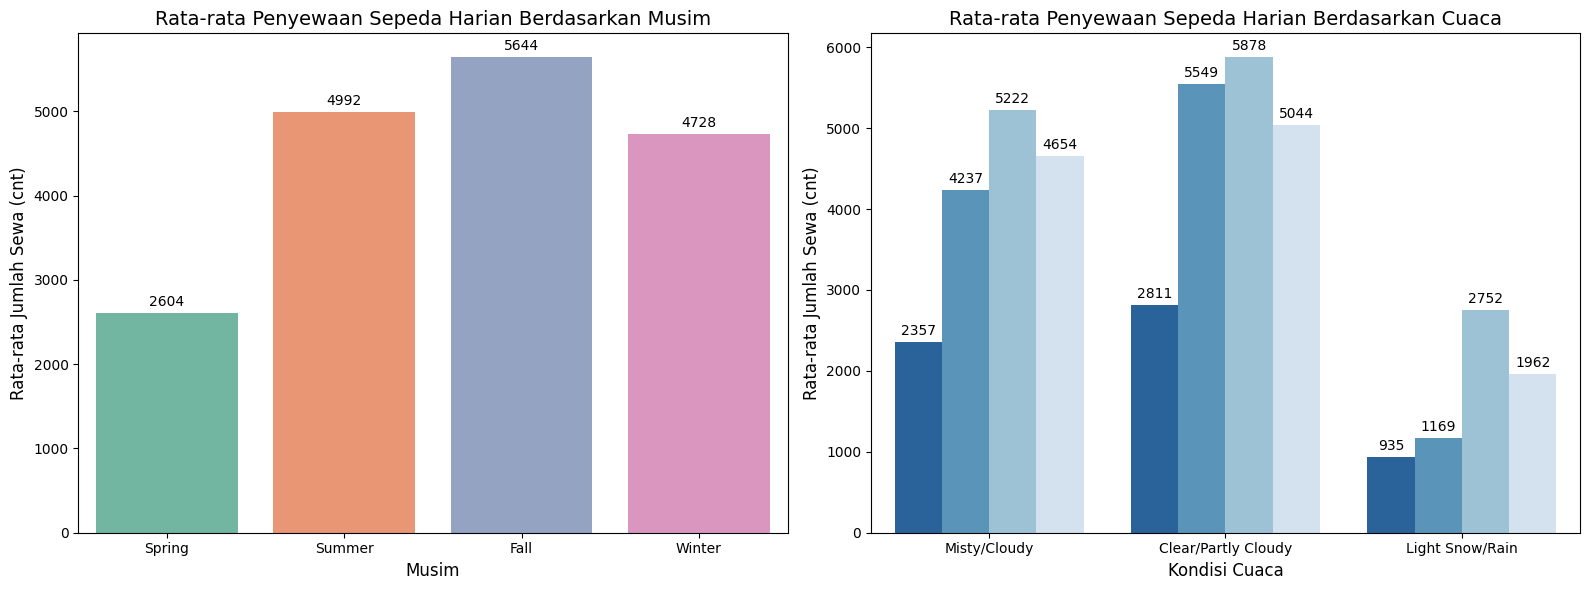

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visualisasi 1: Berdasarkan Musim (season_label)
sns.barplot(
    x='season_label',
    y='cnt',
    data=day_df,
    hue='season_label',
    legend=False,
    estimator=np.mean,
    ax=axes[0],
    palette='Set2',
    errorbar=None
)
axes[0].set_title('Rata-rata Penyewaan Sepeda Harian Berdasarkan Musim', fontsize=14)
axes[0].set_xlabel('Musim', fontsize=12)
axes[0].set_ylabel('Rata-rata Jumlah Sewa (cnt)', fontsize=12)

# Menambahkan angka nilai rata-rata di atas setiap bar
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.0f}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points')

# Visualisasi 2: Berdasarkan Cuaca (weather_label)
sns.barplot(
    x='weather_label',
    y='cnt',
    data=day_df,
    hue='season_label',
    legend=False,
    estimator=np.mean,
    ax=axes[1],
    palette='Blues_r',
    errorbar=None
)
axes[1].set_title('Rata-rata Penyewaan Sepeda Harian Berdasarkan Cuaca', fontsize=14)
axes[1].set_xlabel('Kondisi Cuaca', fontsize=12)
axes[1].set_ylabel('Rata-rata Jumlah Sewa (cnt)', fontsize=12)

# Menambahkan angka nilai rata-rata di atas setiap bar
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.0f}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), textcoords='offset points')

plt.tight_layout()
plt.show()

### Pertanyaan 2: Pada jam berapa saja terjadi lonjakan puncak (peak hours) volume penyewaan per jam antara pengguna terdaftar (registered) dan pengguna kasual (casual) pada hari kerja dibandingkan akhir pekan selama tahun 2011–2012?

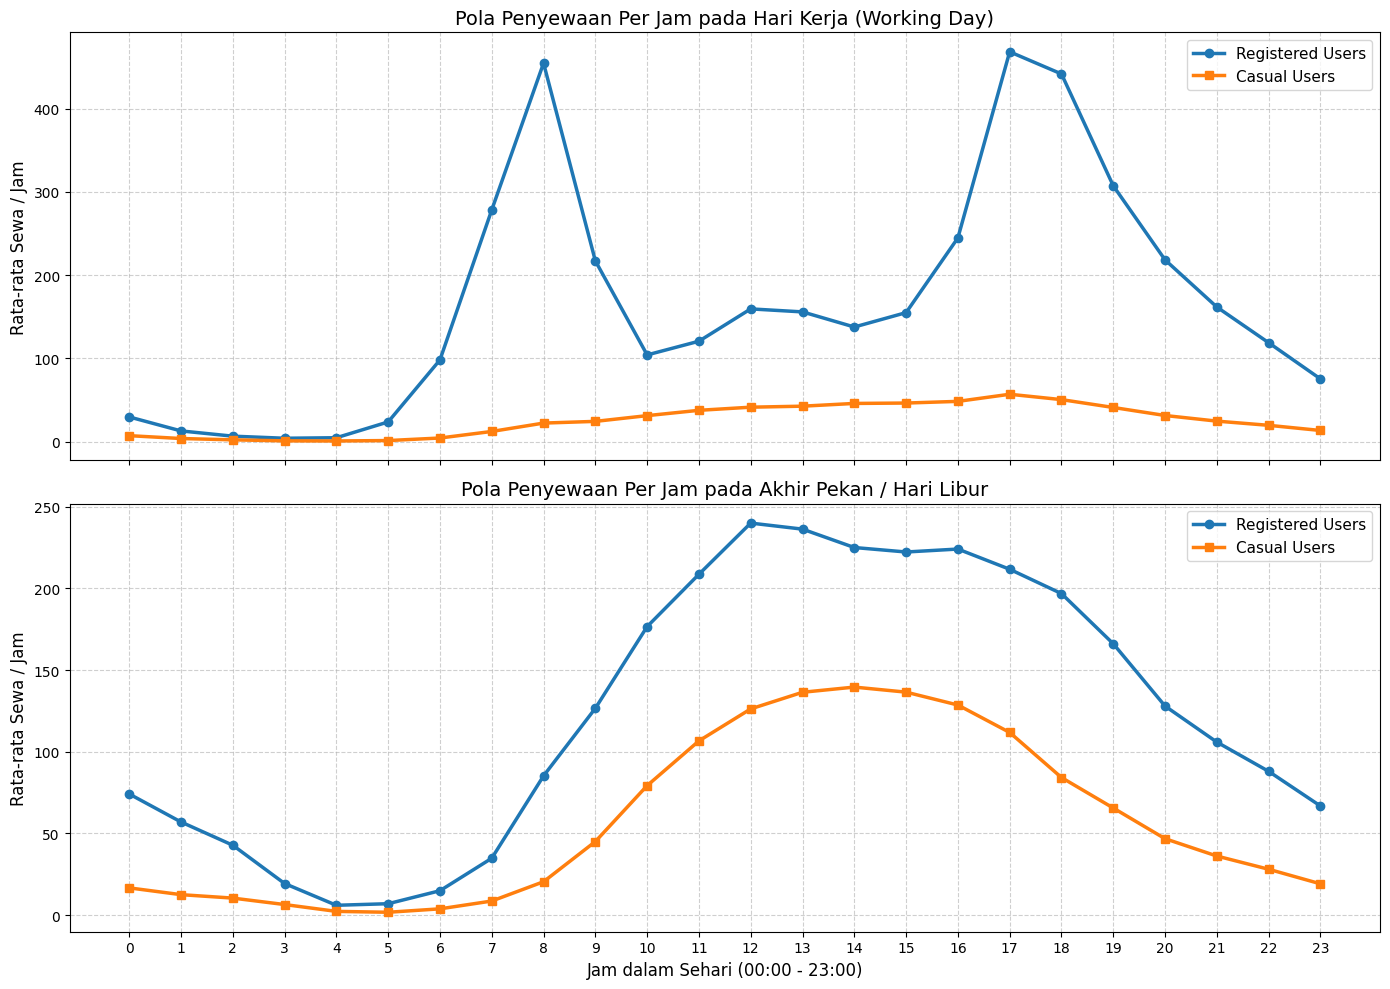

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Graph 1: Hari Kerja (Working Day = 1)
working_df = hour_df[hour_df['workingday'] == 1].groupby('hr')[['casual', 'registered']].mean().reset_index()
axes[0].plot(working_df['hr'], working_df['registered'], label='Registered Users', color='tab:blue', linewidth=2.5, marker='o')
axes[0].plot(working_df['hr'], working_df['casual'], label='Casual Users', color='tab:orange', linewidth=2.5, marker='s')
axes[0].set_title('Pola Penyewaan Per Jam pada Hari Kerja (Working Day)', fontsize=14)
axes[0].set_ylabel('Rata-rata Sewa / Jam', fontsize=12)
axes[0].set_xticks(range(0, 24))
axes[0].legend(fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Graph 2: Akhir Pekan / Hari Libur (Working Day = 0)
non_working_df = hour_df[hour_df['workingday'] == 0].groupby('hr')[['casual', 'registered']].mean().reset_index()
axes[1].plot(non_working_df['hr'], non_working_df['registered'], label='Registered Users', color='tab:blue', linewidth=2.5, marker='o')
axes[1].plot(non_working_df['hr'], non_working_df['casual'], label='Casual Users', color='tab:orange', linewidth=2.5, marker='s')
axes[1].set_title('Pola Penyewaan Per Jam pada Akhir Pekan / Hari Libur', fontsize=14)
axes[1].set_xlabel('Jam dalam Sehari (00:00 - 23:00)', fontsize=12)
axes[1].set_ylabel('Rata-rata Sewa / Jam', fontsize=12)
axes[1].set_xticks(range(0, 24))
axes[1].legend(fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- xxx
- xxx

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Faktor iklim dan cuaca memiliki pengaruh yang sangat signifikan terhadap total rata-rata penyewaan sepeda harian sepanjang tahun 2011–2012. Penyewaan mencapai resi tertinggi pada **Musim Gugur (Fall)** dengan rata-rata **5.644 sewa/hari** dan kondisi cuaca **Cerah/Berawan Sedikit (Clear/Partly Cloudy)** sebesar **4.877 sewa/hari**. Sebaliknya, tingkat penyewaan mengalami penurunan drastis pada kondisi cuaca **Hujan/Salju Ringan (Light Snow/Rain)** yang hanya mencapai **1.803 sewa/hari** serta pada **Musim Semi (Spring)** dengan rata-rata **2.604 sewa/hari**.
- **Conclusion pertanyaan 2:** Terdapat perbedaan pola jam sibuk (*peak hours*) yang sangat kontras antara jenis pengguna terdaftar (*registered*) dan kasual (*casual*) selama periode 2011–2012:
  1. Pada **Hari Kerja (Working Day)**, penggunaan didominasi oleh pengguna terdaftar (*Registered*) dengan dua puncak utama di jam berangkat kerja (**08:00 pagi**, ~477 sewa/jam) dan jam pulang kerja (**17:00–18:00 sore**, ~461–525 sewa/jam) untuk kebutuhan komuter.
  2. Pada **Akhir Pekan / Hari Libur**, penyewaan relatif landai di pagi hari dan baru meningkat dari siang hingga sore hari (**12:00–16:00**) dengan puncak di jam **13:00–14:00**, di mana kontribusi pengguna kasual (*Casual*) meningkat signifikan (~110–125 sewa/jam) untuk aktivitas rekreasi.

**Rekomendasi Action Item:**
- **Manajemen Pasokan & Logistik Armada**:
  - Lakukan pemindahan dan re-alokasi pasokan sepeda ke stasiun transit atau area perkantoran sebelum jam 08:00 pagi dan sebelum jam 17:00 sore pada hari kerja untuk mengantisipasi lonjakan pengguna komuter.
  - Pindahkan sebagian armada ke stasiun di sekitar lokasi rekreasi, taman, atau pusat perbelanjaan pada akhir pekan mulai pukul 11:00 siang.
- **Penjadwalan Pemeliharaan Armada (Maintenance Routine)**:
  - Lakukan pemeliharaan dan servis berkala armada sepeda pada **Musim Semi (Spring)** atau saat prediksi cuaca menunjukkan hujan/salju ringan, karena pada periode ini permintaan penyewaan sedang berada pada titik terendah.
- **Strategi Konversi Pelanggan (Casual to Registered)**:
  - Berikan penawaran diskon promosi *membership* atau program langganan khusus kepada pengguna kasual yang aktif menyewa pada akhir pekan di jam 12:00–16:00 agar mendorong mereka bertransisi menjadi pengguna terdaftar (*Registered*).